## Setup and shared definitions

In [ ]:
!pip -q install panns_inference librosa soundfile scikit-learn matplotlib seaborn
from google.colab import drive
drive.mount('/content/drive')
!test -d ESC-50 || git clone -q https://github.com/karolpiczak/ESC-50.git

Mounted at /content/drive


In [ ]:
import numpy as np, pandas as pd, librosa, torch, torch.nn as nn, random, time
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

In [ ]:
P = '/content/drive/MyDrive/Colab Notebooks/ESC/'
meta = pd.read_csv('ESC-50/meta/esc50.csv')
files, y, folds = meta.filename.tolist(), meta.target.values, meta.fold.values
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


In [ ]:
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def load_audio(fn, sr):
    w, _ = librosa.load(f'ESC-50/audio/{fn}', sr=sr)
    return np.pad(w, (0, max(0, 5*sr - len(w))))[:5*sr]

def logmel_wave(w):
    m = librosa.feature.melspectrogram(y=w, sr=22050, n_fft=1024, hop_length=512, n_mels=64)
    return librosa.power_to_db(m, ref=np.max).astype('float32')


In [ ]:
X_mel  = np.load(P + 'mel.npy')          # (2000,1,64,216)
X_pann = np.load(P + 'pann_emb.npy')     # (2000,2048)
print(X_mel.shape, X_pann.shape)


(2000, 1, 64, 216) (2000, 2048)


In [ ]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))

def make_cnn():
    return nn.Sequential(block(1,32), block(32,64), block(64,128), block(128,256),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256,50))

## Pretrained model, all 5 folds



In [ ]:
def eval_pann(test_fold):
    tr, te = folds != test_fold, folds == test_fold
    sc = StandardScaler().fit(X_pann[tr])
    clf = LogisticRegression(max_iter=3000).fit(sc.transform(X_pann[tr]), y[tr])
    pred = clf.predict(sc.transform(X_pann[te]))
    return (pred == y[te]).mean(), pred

pann_rows, oof_pann = [], np.zeros(len(y), dtype=int)
for f in range(1, 6):
    acc, pred = eval_pann(f)
    oof_pann[folds == f] = pred
    pann_rows.append(dict(model='Pretrained (PANNs+LogReg)', cfg='-', seed=0, fold=f, acc=acc))
    print(f'fold {f}: {acc:.3f}')

fold 1: 0.912
fold 2: 0.940
fold 3: 0.915
fold 4: 0.950
fold 5: 0.905


## From-scratch CNN with augmentation ablation

In [ ]:
def augment(x, cfg):
    x = x.clone(); B, _, F, T = x.shape
    if 'shift' in cfg:                                   # time shift
        for i in range(B):
            x[i] = torch.roll(x[i], int(torch.randint(-T//5, T//5+1, (1,))), dims=-1)
    if 'noise' in cfg:                                   # Gaussian noise on spectrogram
        x = x + 0.1 * torch.randn_like(x)
    if 'mask' in cfg:                                    # SpecAugment-style masks
        for i in range(B):
            for _ in range(2):
                fw = int(torch.randint(0, 9, (1,)));  f0 = int(torch.randint(0, F-fw+1, (1,)))
                tw = int(torch.randint(0, 25, (1,))); t0 = int(torch.randint(0, T-tw+1, (1,)))
                x[i, :, f0:f0+fw, :] = 0; x[i, :, :, t0:t0+tw] = 0
    return x

CONFIGS = {'none': [], 'shift': ['shift'], 'noise': ['noise'], 'mask': ['mask'],
           'all': ['shift', 'noise', 'mask']}

def train_scratch(test_fold, seed, cfg, epochs=30, bs=32, lr=1e-3):
    seed_all(seed)
    tr = folds != test_fold
    mu, sd = X_mel[tr].mean(), X_mel[tr].std()
    Xtr = torch.tensor((X_mel[tr]-mu)/sd).to(device); ytr = torch.tensor(y[tr]).to(device)
    net = make_cnn().to(device); opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]
            opt.zero_grad()
            loss = nn.functional.cross_entropy(net(augment(Xtr[idx], cfg)), ytr[idx])
            loss.backward(); opt.step()
    return net, mu, sd

def predict(net, X, mu, sd):
    net.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), 100):
            out.append(net(torch.tensor((X[i:i+100]-mu)/sd).to(device)).argmax(1).cpu().numpy())
    return np.concatenate(out)

# ---- QUICK TEST FIRST: FOLDS=[5], SEEDS=[0], EPOCHS=1. Then switch to the full settings. ----
FOLDS, SEEDS, EPOCHS = [1,2,3,4,5], [0,1,2], 30

rows, oof, models, times = [], {}, {}, {}
for cfg_name, cfg in CONFIGS.items():
    for seed in SEEDS:
        oof[(cfg_name, seed)] = np.zeros(len(y), dtype=int)
        for f in FOLDS:
            t0 = time.time()
            net, mu, sd = train_scratch(f, seed, cfg, epochs=EPOCHS)
            te = folds == f
            pred = predict(net, X_mel[te], mu, sd)
            oof[(cfg_name, seed)][te] = pred
            acc = (pred == y[te]).mean()
            rows.append(dict(model='Scratch CNN', cfg=cfg_name, seed=seed, fold=f, acc=acc))
            times.setdefault(cfg_name, []).append(time.time()-t0)
            if seed == 0 and cfg_name in ('none', 'all'):
                models[(cfg_name, f)] = (net, mu, sd)       # kept for the noise test
            print(f'{cfg_name} | seed {seed} | fold {f}: {acc:.3f}')

none | seed 0 | fold 1: 0.677
none | seed 0 | fold 2: 0.713
none | seed 0 | fold 3: 0.695
none | seed 0 | fold 4: 0.688
none | seed 0 | fold 5: 0.655
none | seed 1 | fold 1: 0.700
none | seed 1 | fold 2: 0.665
none | seed 1 | fold 3: 0.680
none | seed 1 | fold 4: 0.640
none | seed 1 | fold 5: 0.713
none | seed 2 | fold 1: 0.700
none | seed 2 | fold 2: 0.650
none | seed 2 | fold 3: 0.695
none | seed 2 | fold 4: 0.642
none | seed 2 | fold 5: 0.623
shift | seed 0 | fold 1: 0.682
shift | seed 0 | fold 2: 0.720
shift | seed 0 | fold 3: 0.688
shift | seed 0 | fold 4: 0.690
shift | seed 0 | fold 5: 0.635
shift | seed 1 | fold 1: 0.735
shift | seed 1 | fold 2: 0.715
shift | seed 1 | fold 3: 0.672
shift | seed 1 | fold 4: 0.690
shift | seed 1 | fold 5: 0.670
shift | seed 2 | fold 1: 0.670
shift | seed 2 | fold 2: 0.733
shift | seed 2 | fold 3: 0.700
shift | seed 2 | fold 4: 0.657
shift | seed 2 | fold 5: 0.677
noise | seed 0 | fold 1: 0.630
noise | seed 0 | fold 2: 0.605
noise | seed 0 | fold 3

## Results table, figure, and efficiency (RQ1-RQ3)

                       model    cfg      report
0  Pretrained (PANNs+LogReg)      -  92.4 ± 1.9
1                Scratch CNN    all  61.3 ± 3.1
2                Scratch CNN   mask  65.8 ± 2.6
3                Scratch CNN  noise  57.9 ± 4.5
4                Scratch CNN   none  67.6 ± 1.6
5                Scratch CNN  shift  68.9 ± 2.3


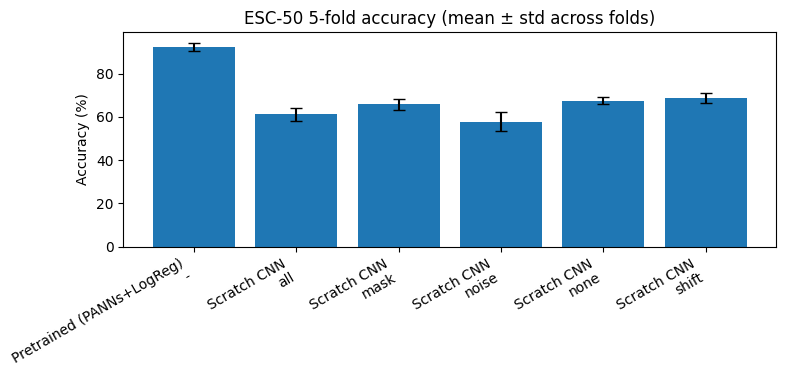

Scratch CNN params: 401650
Mean train time per run (s): {'none': np.float64(33.0), 'shift': np.float64(32.9), 'noise': np.float64(32.8), 'mask': np.float64(33.3), 'all': np.float64(33.5)}


In [ ]:
df = pd.DataFrame(pann_rows + rows)
fold_mean = df.groupby(['model', 'cfg', 'fold']).acc.mean().reset_index()   # average over seeds
summary = fold_mean.groupby(['model', 'cfg']).acc.agg(['mean', 'std']).reset_index()
summary['report'] = (summary['mean']*100).round(1).astype(str) + ' ± ' + (summary['std']*100).round(1).astype(str)
print(summary[['model', 'cfg', 'report']])
summary.to_csv(P + 'summary.csv', index=False); df.to_csv(P + 'all_runs.csv', index=False)

plt.figure(figsize=(8,4))
plt.bar(summary.model + '\n' + summary.cfg, summary['mean']*100, yerr=summary['std']*100, capsize=4)
plt.ylabel('Accuracy (%)'); plt.title('ESC-50 5-fold accuracy (mean ± std across folds)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.savefig(P + 'fig_accuracy.png', dpi=200); plt.show()

# efficiency (RQ3)
print('Scratch CNN params:', sum(p.numel() for p in make_cnn().parameters()))
print('Mean train time per run (s):', {k: round(np.mean(v), 1) for k, v in times.items()})

## Error analysis (RQ4)

In [14]:
cats = meta.drop_duplicates('target').set_index('target').category
best = summary[summary.model == 'Scratch CNN'].sort_values('mean').iloc[-1].cfg   # best scratch config
oof_scratch = oof[(best, 0)]
print('best scratch config:', best)

def top_confusions(pred, k=8):
    cm = confusion_matrix(y, pred, labels=range(50)); np.fill_diagonal(cm, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:k], cm.shape))[0]
    return pd.DataFrame([(cats[a], cats[b], cm[a, b]) for a, b in idx], columns=['true', 'predicted', 'count'])

print('Pretrained top confusions:\n', top_confusions(oof_pann))
print('Scratch top confusions:\n', top_confusions(oof_scratch))

pc = pd.DataFrame({'class': [cats[i] for i in range(50)],
    'pretrained': [(oof_pann[y==i]==i).mean() for i in range(50)],
    'scratch':    [(oof_scratch[y==i]==i).mean() for i in range(50)]})
pc['gap'] = pc.pretrained - pc.scratch
print(pc.sort_values('gap').head(5), '\n', pc.sort_values('gap').tail(5))   # where pretraining helps most/least
pc.to_csv(P + 'per_class.csv', index=False)

best scratch config: shift
Pretrained top confusions:
           true        predicted  count
0   helicopter         airplane      5
1   helicopter  washing_machine      5
2     airplane       helicopter      4
3     airplane             wind      4
4   helicopter             wind      4
5   helicopter           engine      3
6       engine         chainsaw      3
7  mouse_click  keyboard_typing      3
Scratch top confusions:
           true     predicted  count
0        sheep           cow     15
1   helicopter      airplane     12
2          hen      laughing     10
3  water_drops    clock_tick      7
4     coughing      sneezing      7
5       engine    helicopter      7
6     car_horn           cow      7
7         wind  thunderstorm      6
              class  pretrained  scratch    gap
19     thunderstorm       0.950    0.975 -0.025
20      crying_baby       0.950    0.900  0.050
30  door_wood_knock       0.975    0.925  0.050
39   glass_breaking       0.900    0.850  0.050
21   

## Noise robustness (RQ5)

In [ ]:
from panns_inference import AudioTagging
at = AudioTagging(checkpoint_path=None, device=device)

def add_noise(w, snr_db, rng):
    p = np.mean(w**2) + 1e-10
    return w + rng.randn(len(w)) * np.sqrt(p / 10**(snr_db/10))

SNRS = [20, 10, 0]
noisy = {}
for snr in SNRS:
    rng = np.random.RandomState(0)
    mel = np.stack([logmel_wave(add_noise(load_audio(f, 22050), snr, rng)) for f in files])[:, None]
    emb = []
    for i in range(0, len(files), 32):
        b = np.stack([add_noise(load_audio(f, 32000), snr, rng) for f in files[i:i+32]])
        emb.append(at.inference(b)[1])
    noisy[snr] = (mel, np.concatenate(emb))

rob = []
for f in FOLDS:
    tr, te = folds != f, folds == f
    sc = StandardScaler().fit(X_pann[tr])
    clf = LogisticRegression(max_iter=3000).fit(sc.transform(X_pann[tr]), y[tr])
    for snr in SNRS:
        mel_n, emb_n = noisy[snr]
        rob.append(dict(model='Pretrained', snr=snr, fold=f, acc=(clf.predict(sc.transform(emb_n[te])) == y[te]).mean()))
        for cfg_name in ('none', 'all'):
            net, mu, sd = models[(cfg_name, f)]
            rob.append(dict(model=f'Scratch ({cfg_name})', snr=snr, fold=f,
                            acc=(predict(net, mel_n[te], mu, sd) == y[te]).mean()))
rob = pd.DataFrame(rob)
print(rob.groupby(['model', 'snr']).acc.mean().unstack().round(3))
rob.to_csv(P + 'robustness.csv', index=False)

Checkpoint path: /root/panns_data/Cnn14_mAP=0.431.pth
GPU number: 1
snr                0      10     20
model                              
Pretrained      0.326  0.683  0.875
Scratch (all)   0.050  0.218  0.434
Scratch (none)  0.070  0.342  0.479
